# Imports

In [1]:
from pesummary.io import read;

from pycbc.inference.io import loadfile;
from pycbc import conversions as cvs;
from pycbc import cosmology as cos;

import numpy as np
import matplotlib.pyplot as pp
import seaborn as sns

import pandas as pd

pp.rcParams.update({
    "text.usetex": False,  # 启用 LaTeX 渲染
    # "font.family": "serif",  # 可选：设置字体为衬线字体（与 LaTeX 风格一致）
    # "font.serif": ["Times New Roman", "Computer Modern Roman"],  # 可选：指定字体
});
pp.rcParams.update(pp.rcParamsDefault);

/home/chendawww/Software/anaconda3/envs/pycbc/lib/python3.12/site-packages/gwpy/time/__init__.py:36: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  from lal import LIGOTimeGPS


$N = - \frac{3}{128}\frac{1}{\eta}\pi^{-5/3}\\
$
\begin{aligned}
-\phi = Nf^{5/3}(\cdots + \phi_j f^{j/3} + \phi_{jl} f^{j/3}\log{f})
    = -f^{5/3}(\cdots + \psi_j f^{j/3} + \psi_{jl} f^{j/3}\log{f})\\
\end{aligned}

\begin{aligned}
-\phi^\prime = N((\cdots)^\prime + \left(\frac{j-8}{3}\phi_j + \phi_{jl}\right) f^{(j-8)/3} + \frac{j-8}{3}\phi_{jl} f^{(j-8)/3}\log{f})\\
    = (M)^{-8/3} \frac{5}{128 \pi^{5/3}}((\cdots)^\prime + \left(\frac{8-j}{5}\phi_j - \frac{3}{5}\phi_{jl}\right) f^{(j-8)/5} + \frac{8-j}{3}\phi_{jl} f^{(j-8)/3}\log{f})
    = \\
\end{aligned}

# Util Function

In [2]:
def augment_OGC_result(samples, approximant='SEOBNRv4PHM', f_ref=20) :
    # lalsuite里面只有SEOBNR的几个模型能算m_f, a_f
    samples = samples.add_fields(cvs.mass1_from_mchirp_q(samples['srcmchirp'], samples['q']), 'mass1')
    samples = samples.add_fields(cvs.mass2_from_mchirp_q(samples['srcmchirp'], samples['q']), 'mass2')
    samples = samples.add_fields(cvs.eta_from_mass1_mass2(samples['mass1'], samples['mass2']), 'eta')

    samples = samples.add_fields(cvs.mtotal_from_mass1_mass2(samples['mass1'], samples['mass2']), 'Mtot')
    samples = samples.add_fields(samples['srcmchirp'], 'Mchirp')
    # samples = samples.add_fields(cvs.eta_from_mass1_mass2(samples['mass1'], samples['mass2']), 'eta')
    samples = samples.add_fields(cvs.invq_from_mass1_mass2(samples['mass1'], samples['mass2']), 'invq')

    samples = samples.add_fields(cvs.chi_eff_from_spherical(samples['mass1'], samples['mass2'], samples['spin1_a'], samples['spin1_polar'], samples['spin2_a'], samples['spin2_polar']), 'chi_eff')
    samples = samples.add_fields(cvs.chi_p_from_spherical(samples['mass1'], samples['mass2'], samples['spin1_a'], samples['spin1_azimuthal'], samples['spin1_polar'], samples['spin2_a'],samples['spin1_azimuthal'], samples['spin2_polar']), 'chi_p')

    samples = samples.add_fields(cos.distance_from_comoving_volume(samples['comoving_volume']), 'distance')
    samples = samples.add_fields(cos.redshift_from_comoving_volume(samples['comoving_volume']), 'redshift')
    
    temp = {}
    temp['spin1_x'], temp['spin1_y'], temp['spin1_z'] = cvs._spherical_to_cartesian(samples['spin1_a'], samples['spin1_azimuthal'], samples['spin1_polar'])
    temp['spin2_x'], temp['spin2_y'], temp['spin2_z'] = cvs._spherical_to_cartesian(samples['spin2_a'], samples['spin2_azimuthal'], samples['spin2_polar'])

    samples = samples.add_fields(temp['spin1_x'], 'spin1_x')
    samples = samples.add_fields(temp['spin1_y'], 'spin1_y')
    samples = samples.add_fields(temp['spin1_z'], 'spin1_z')
    samples = samples.add_fields(temp['spin2_x'], 'spin2_x')
    samples = samples.add_fields(temp['spin2_y'], 'spin2_y')
    samples = samples.add_fields(temp['spin2_z'], 'spin2_z')


    # 这两个算得很慢
    # samples = samples.add_fields(cvs.final_mass_from_initial(samples['mass1'], samples['mass2'], samples['spin1_x'], samples['spin1_y'], samples['spin1_z'], samples['spin2_x'], samples['spin2_y'], samples['spin2_z'], approximant=approximant, f_ref=f_ref), 'm_f')
    # samples = samples.add_fields(cvs.final_spin_from_initial(samples['mass1'], samples['mass2'], samples['spin1_x'], samples['spin1_y'], samples['spin1_z'], samples['spin2_x'], samples['spin2_y'], samples['spin2_z'], approximant=approximant, f_ref=f_ref), 'a_f')

    return samples

def augment_OGC_XAS_result(samples, approximant='SEOBNRv4PHM', f_ref=20) :
    # lalsuite里面只有SEOBNR的几个模型能算m_f, a_f
    samples = samples.add_fields(cvs.mass1_from_mchirp_q(samples['srcmchirp'], samples['q']), 'mass1')
    samples = samples.add_fields(cvs.mass2_from_mchirp_q(samples['srcmchirp'], samples['q']), 'mass2')
    samples = samples.add_fields(cvs.eta_from_mass1_mass2(samples['mass1'], samples['mass2']), 'eta')

    samples = samples.add_fields(cvs.mtotal_from_mass1_mass2(samples['mass1'], samples['mass2']), 'Mtot')
    samples = samples.add_fields(samples['srcmchirp'], 'Mchirp')
    # samples = samples.add_fields(cvs.eta_from_mass1_mass2(samples['mass1'], samples['mass2']), 'eta')
    samples = samples.add_fields(cvs.invq_from_mass1_mass2(samples['mass1'], samples['mass2']), 'invq')

    # samples = samples.add_fields(cvs.chi_eff_from_spherical(samples['mass1'], samples['mass2'], samples['spin1_a'], samples['spin1_polar'], samples['spin2_a'], samples['spin2_polar']), 'chi_eff')
    # samples = samples.add_fields(cvs.chi_p_from_spherical(samples['mass1'], samples['mass2'], samples['spin1_a'], samples['spin1_azimuthal'], samples['spin1_polar'], samples['spin2_a'],samples['spin1_azimuthal'], samples['spin2_polar']), 'chi_p')

    samples = samples.add_fields(cos.distance_from_comoving_volume(samples['comoving_volume']), 'distance')
    samples = samples.add_fields(cos.redshift_from_comoving_volume(samples['comoving_volume']), 'redshift')
    
    def chi_hat_PN(m1,m2,chi1,chi2) :
        eta = cvs.eta_from_mass1_mass2(m1,m2)
        N = 1 - 76/133*eta
        chi_eff = cvs.chi_eff(m1,m2,chi1,chi2)
        term = -38/113*eta*(chi1+chi2)
        chi_PN = chi_eff + term
        return chi_PN / N
        # cvs.chi_eff(samples['mass1'], samples['mass2'],samples['spin1z'],samples['spin2z'])
    samples = samples.add_fields(chi_hat_PN(samples['mass1'], samples['mass2'],samples['spin1z'],samples['spin2z']), 'chi_hat_PN')
    
    temp = {}
    # temp['spin1_x'], temp['spin1_y'], temp['spin1_z'] = cvs._spherical_to_cartesian(samples['spin1_a'], samples['spin1_azimuthal'], samples['spin1_polar'])
    # temp['spin2_x'], temp['spin2_y'], temp['spin2_z'] = cvs._spherical_to_cartesian(samples['spin2_a'], samples['spin2_azimuthal'], samples['spin2_polar'])

    # samples = samples.add_fields(temp['spin1_x'], 'spin1_x')
    # samples = samples.add_fields(temp['spin1_y'], 'spin1_y')
    # samples = samples.add_fields(samples['spin1z'], 'spin1z')
    # samples = samples.add_fields(temp['spin2_x'], 'spin2_x')
    # samples = samples.add_fields(temp['spin2_y'], 'spin2_y')
    # samples = samples.add_fields(samples['spin2z'], 'spin2z')


    # 这两个算得很慢
    # samples = samples.add_fields(cvs.final_mass_from_initial(samples['mass1'], samples['mass2'], samples['spin1_x'], samples['spin1_y'], samples['spin1_z'], samples['spin2_x'], samples['spin2_y'], samples['spin2_z'], approximant=approximant, f_ref=f_ref), 'm_f')
    # samples = samples.add_fields(cvs.final_spin_from_initial(samples['mass1'], samples['mass2'], samples['spin1_x'], samples['spin1_y'], samples['spin1_z'], samples['spin2_x'], samples['spin2_y'], samples['spin2_z'], approximant=approximant, f_ref=f_ref), 'a_f')

    return samples

# Data Reading and Pre-processing

## OGC Posteriors

In [3]:
posteriors_path = "/mnt/d/Documents/workspace/课题/workspace/Local/Public/posteriors"

samples = {}
samples['GW150914'] = {}
samples['GW150914_095045'] = {}
samples['GW151012'] = {}
samples['GW151226'] = {}
samples['GW170104'] = {}
samples['GW170608'] = {}
samples['GW170729'] = {}
samples['GW170809'] = {}
samples['GW170818'] = {}
samples['GW170823'] = {}
samples['GW170814'] = {}
samples['GW200129_065458'] = {}

event_id = "GW170104"


In [4]:
cpsijs = ['gr', 'cpsi0', 'cpsi2', 'cpsi3', 'cpsi4', 'cpsi5l', 'cpsi6', 'cpsi6l']
dchis = ['gr', 'dchi0', 'dchi2', 'dchi3', 'dchi4', 'dchi5l', 'dchi6', 'dchi6l']
orders = ['gr', '0', '2', '3', '4', '5l', '6', '6l']
event_ids = [
    # 'GW150914',
    'GW150914_095045',
    'GW151012',
    'GW151226',
    'GW170104',
    'GW170608',
    'GW170729',
    'GW170809',
    'GW170818',
    'GW170823',
    'GW170814'
]

In [5]:
for event_id in event_ids :
    for cpsij in cpsijs :
        label=f"{event_id}, {cpsij}"
        posterior_file_name=f"{event_id}_{cpsij}.hdf"
        result_posterior_path='OGC/' + event_id + ''
        print(posteriors_path + '/' + result_posterior_path + '/' + posterior_file_name)
        fp = loadfile(posteriors_path + '/' + result_posterior_path + '/' + posterior_file_name, 'r')
        samples[event_id][cpsij] = fp.read_samples(fp['samples'].keys())
        samples[event_id][cpsij] = augment_OGC_XAS_result(samples[event_id][cpsij])
        samples[event_id][cpsij] = pd.DataFrame(samples[event_id][cpsij])
        samples[event_id][cpsij].attrs['label'] = label

/mnt/d/Documents/workspace/课题/workspace/Local/Public/posteriors/OGC/GW150914_095045/GW150914_095045_gr.hdf


/mnt/d/Documents/workspace/课题/workspace/Local/Public/posteriors/OGC/GW150914_095045/GW150914_095045_cpsi0.hdf
/mnt/d/Documents/workspace/课题/workspace/Local/Public/posteriors/OGC/GW150914_095045/GW150914_095045_cpsi2.hdf
/mnt/d/Documents/workspace/课题/workspace/Local/Public/posteriors/OGC/GW150914_095045/GW150914_095045_cpsi3.hdf
/mnt/d/Documents/workspace/课题/workspace/Local/Public/posteriors/OGC/GW150914_095045/GW150914_095045_cpsi4.hdf
/mnt/d/Documents/workspace/课题/workspace/Local/Public/posteriors/OGC/GW150914_095045/GW150914_095045_cpsi5l.hdf
/mnt/d/Documents/workspace/课题/workspace/Local/Public/posteriors/OGC/GW150914_095045/GW150914_095045_cpsi6.hdf
/mnt/d/Documents/workspace/课题/workspace/Local/Public/posteriors/OGC/GW150914_095045/GW150914_095045_cpsi6l.hdf
/mnt/d/Documents/workspace/课题/workspace/Local/Public/posteriors/OGC/GW151012/GW151012_gr.hdf
/mnt/d/Documents/workspace/课题/workspace/Local/Public/posteriors/OGC/GW151012/GW151012_cpsi0.hdf
/mnt/d/Documents/workspace/课题/workspace

In [6]:
samples_quantiles = {}
for event_id in event_ids :
    samples_quantiles[event_id] = {}
    for order in orders :
        cpsij = "cpsi" + order
        dchij = "dchi" + order
        if order == "gr" :
            quantile_table = samples[event_id]["gr"].quantile([0.05,0.50,0.95])[["mass1","mass2","spin1z","spin2z","chi_hat_PN"]]
            samples_quantiles[event_id]["gr"] = quantile_table
        else :
            quantile_table = samples[event_id][cpsij].quantile([0.05,0.50,0.95])[["mass1","mass2","spin1z","spin2z","chi_hat_PN",dchij]]
            samples_quantiles[event_id][cpsij] = quantile_table

In [7]:
width_ratios = {}
median_ratios = {}
for event_id in event_ids :
    width_ratios[event_id] = {}
    median_ratios[event_id] = {}
    gr_table = samples_quantiles[event_id]["gr"]
    gr_q05 = samples_quantiles[event_id]["gr"].loc[0.05]
    gr_q50 = samples_quantiles[event_id]["gr"].loc[0.50]
    gr_q95 = samples_quantiles[event_id]["gr"].loc[0.95]
    for order in orders :
        cpsij = "cpsi" + order
        dchij = "dchi" + order
        if order != "gr" :
            quantile_table = samples_quantiles[event_id][cpsij]
            q05 = quantile_table.loc[0.05]
            q50 = quantile_table.loc[0.50]
            q95 = quantile_table.loc[0.95]
            width_ratios[event_id][cpsij] = (q95 - q05) / (gr_q95 - gr_q05)
            median_ratios[event_id][cpsij] = q50 / gr_q50
            
        

In [8]:
wr = {}
md = {}
for par in ["mass1","mass2","spin1z","spin2z","chi_hat_PN"] :
    wr[par] = np.ndarray((len(orders)-1, len(event_ids)))
    md[par] = np.ndarray((len(orders)-1, len(event_ids)))
    for i, order in enumerate(orders[1:]) :
        cpsij = "cpsi" + order
        dchij = "dchi" + order
        for j, event_id in enumerate(event_ids) :
            if order != "gr" :
                wr[par][i][j] = width_ratios[event_id][cpsij][par]
                md[par][i][j] = median_ratios[event_id][cpsij][par]

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def plot_heatmap(data, par_latex="") :
    rows = ['GW150914', 'GW151012', 'GW151226', 'GW170104', 'GW170608',
            'GW170729', 'GW170809', 'GW170814', 'GW170818', 'GW170823']
    cols = ['0', '2', '3', '4', '5l', '6', '6l']
    new_rows = ['GW150914', 'GW170814', 'GW170608', 'GW170104', 'GW151226',
                'GW170809', 'GW170823', 'GW170818', 'GW170729', "GW151012"]

    # 创建映射字典
    row_to_data = dict(zip(rows, data))
    new_data = []
    for row in new_rows:
        new_data.append(row_to_data[row])
        
    data = new_data
    rows = new_rows

    df = pd.DataFrame(data, index=rows, columns=cols)

    # 核心：对数变换（10为底），+1e-6避免log(0)出现-inf报错
    df_log = np.log10(df + 1e-6)

    # 绘制热力图（颜色基于对数后的数据，标注保留原始值）
    plt.figure(figsize=(10, 10), dpi=150)
    # imshow渲染对数后的数据，配色保留Blues，vmin/vmax适配对数范围
    im = plt.imshow(df_log, cmap='Reds', 
                    vmin=-1,  # 对数后最小值（约-6，对应原始值1e-6）
                    vmax=1,  # 对数后最大值（约2.81，对应原始值646.926）
                    aspect='auto')

    # 添加数值标注（显示原始值，保留4位小数）
    for i in range(len(df.index)):
        for j in range(len(df.columns)):
            val = df.iloc[i, j]
            if not np.isnan(val):
                # 调整数值颜色阈值：原始值>10时用白色（适配深色背景），否则黑色
                text_color = 'white' if val > 10 else 'black'
                plt.text(j, i, f'{val:.4f}', 
                        ha='center', va='center', 
                        color=text_color, fontsize=8)

    # 设置坐标轴刻度（对应行/列名）
    plt.xticks(ticks=np.arange(len(cols)), labels=cols, fontsize=11)
    plt.yticks(ticks=np.arange(len(rows)), labels=rows, fontsize=11)

    # 添加颜色条（标注对数含义）
    cbar = plt.colorbar(im, shrink=0.8, pad=0.05)
    cbar.set_label('$\\log_{10}$(Width ratio)', fontsize=12)  # 明确颜色条是对数后的值

    plt.title('Heat map of rescaled $\\text{Width ratio}$ of ' + par_latex, fontsize=16, pad=20)

    plt.xlabel('post-Newtonian order', fontsize=14)
    plt.ylabel('Event ID', fontsize=14)
    plt.tight_layout()
    plt.savefig("/mnt/d/Documents/workspace/课题/论文/figs/integrated_analysis/" + "width_ratio_heat_map.pdf")
    plt.show()


In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def plot_heatmap(data, type="width ratio", par_latex="", ax=None, figsize=(10, 10), dpi=150):
    """
    绘制热力图（支持传入外部子图，适配多图组合）
    
    参数:
        data: 输入数据（二维数组，10行7列）
        par_latex: 标题中的LaTeX格式参数
        ax: 外部传入的子图对象（None则自动创建）
        figsize: 图形尺寸 (width, height)（仅ax=None时生效）
        dpi: 分辨率（仅ax=None时生效）
    
    返回:
        fig: 图形对象（ax=None时返回创建的fig，否则返回外部fig）
        ax: 子图对象
        cbar: 颜色条对象
    """
    rows = ['GW150914', 'GW151012', 'GW151226', 'GW170104', 'GW170608',
            'GW170729', 'GW170809', 'GW170814', 'GW170818', 'GW170823']
    cols = ['0', '2', '3', '4', '5l', '6', '6l']
    new_rows = ['GW150914', 'GW170814', 'GW170608', 'GW170104', 'GW151226',
                'GW170809', 'GW170823', 'GW170818', 'GW170729', "GW151012"]

    # 数据维度校验（必须10行7列）
    if np.array(data).shape != (10, 7):
        raise ValueError(f"数据维度错误！需为10行7列，当前是{np.array(data).shape}")

    # 创建映射字典（重排行）
    row_to_data = dict(zip(rows, data))
    new_data = [row_to_data[row] for row in new_rows]
    df = pd.DataFrame(new_data, index=new_rows, columns=cols)

    # 对数变换（避免log(0)）
    df_log = np.log10(df + 1e-6)

    # 关键：如果传入外部ax，复用；否则新建
    if ax is None:
        fig, ax = plt.subplots(figsize=figsize, dpi=dpi)
    else:
        fig = ax.figure  # 从外部ax获取所属的fig

    # 绘制热力图
    im = ax.imshow(df_log, cmap='Reds', vmin=-1, vmax=1, aspect='auto')

    # 添加数值标注
    for i in range(len(df.index)):
        for j in range(len(df.columns)):
            val = df.iloc[i, j]
            if not np.isnan(val):
                text_color = 'white' if val > 10 else 'black'
                ax.text(j, i, f'{val:.4f}', ha='center', va='center', 
                       color=text_color, fontsize=8)

    # 设置坐标轴
    ax.set_xticks(np.arange(len(cols)))
    ax.set_xticklabels(cols, fontsize=11)
    ax.set_yticks(np.arange(len(new_rows)))
    ax.set_yticklabels(new_rows, fontsize=11)

    # 添加颜色条
    cbar = fig.colorbar(im, ax=ax, shrink=0.8, pad=0.05)
    cbar.set_label(f'$\\log_{{10}}$({type})', fontsize=12)

    # 设置标题和轴标签
    ax.set_title('Heat map of rescaled ' + type + ' of ' + par_latex, 
                 fontsize=16, pad=20)
    ax.set_xlabel('post-Newtonian order', fontsize=14)
    ax.set_ylabel('Event ID', fontsize=14)

    return fig, ax, cbar

# # ---------------------- 使用示例 ----------------------
# if __name__ == "__main__":

    

In [31]:
fig_folder = "/mnt/d/Documents/workspace/课题/论文/figs/ratios"
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20,10), dpi=1000)
fig1, ax1, _ = plot_heatmap(md["spin1z"].T, type="median ratio", par_latex="$\\chi_{1L}$", ax=ax1)
fig2, ax2, _ = plot_heatmap(wr["spin1z"].T, par_latex="$\\chi_{1L}$", ax=ax2)
pp.plot()
pp.savefig(fig_folder+"/"+"heatmap_median_width_ratio_chi1L.pdf")

- Quantile ratio

- GW70608, GW151226, GW150914; 至少从这一点可以看出临界概率一定程度上反映了相容情况

- 自旋参数，中位数参考意义有限；$\chi_{1L}$相比$\chi_{2L}$更精准；
- $m_1$，整体偏小一点，宽度比相当；$m_2$，整体更小，宽度比相当；

- $\chi_\text{PN}$
    - GW170823的$\chi_\text{PN}$，配合critical probability
    - GW170809, GW170104

pc受到的影响：
- 首先根据结果从数值本身分个类
- 参数的一些指标的影响
    - median
        - 相合程度
    - 区间宽
        - PN阶数越高；


In [32]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20,10), dpi=1000)

fig1, ax1, _ = plot_heatmap(md["spin2z"].T, type="median ratio", par_latex="$\\chi_{2L}$", ax=ax1)
fig2, ax2, _ = plot_heatmap(wr["spin2z"].T, par_latex="$\\chi_{2L}$", ax=ax2)
pp.plot()
pp.savefig(fig_folder+"/"+"heatmap_median_width_ratio_chi2L.pdf")

In [33]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20,10), dpi=1000)

fig1, ax1, _ = plot_heatmap(md["mass1"].T, type="median ratio", par_latex="$m_1$", ax=ax1)
fig2, ax2, _ = plot_heatmap(wr["mass1"].T, par_latex="$m_1$", ax=ax2)
pp.plot()
pp.savefig(fig_folder+"/"+"heatmap_median_width_ratio_mass1.pdf")

In [34]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20,10), dpi=1000)

fig1, ax1, _ = plot_heatmap(md["mass2"].T, type="median ratio", par_latex="$m_2$", ax=ax1)
fig2, ax2, _ = plot_heatmap(wr["mass2"].T, par_latex="$m_2$", ax=ax2)
pp.plot()
pp.savefig(fig_folder+"/"+"heatmap_median_width_ratio_mass2.pdf")

In [35]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20,10), dpi=1000)

fig1, ax1, _ = plot_heatmap(md["chi_hat_PN"].T, type="median ratio", par_latex="$\\hat{\\chi}_\\text{PN}$", ax=ax1)
fig2, ax2, _ = plot_heatmap(wr["chi_hat_PN"].T, par_latex="$\\hat{\\chi}_\\text{PN}$", ax=ax2)
pp.plot()
pp.savefig(fig_folder+"/"+"heatmap_median_width_ratio_chi_hat_PN.pdf")

# Visualisation

In [15]:
import corner

quantiles = [0.05, 0.50, 0.95]

def plot_parameter(samples: pd.DataFrame, parameter_name, label, type='plot', bins=100, boundary_color='black', quantiles=[0.10, 0.50, 0.90], vlines_colors='blue', if_plot_vlines=False) :
    p = pd.cut(samples[parameter_name], bins=bins).value_counts(sort=False) / len(samples[parameter_name])
    x = pd.cut(samples[parameter_name], bins=bins).cat.categories.left.tolist()
    if type=='plot' :
        pp.plot(x, p, color=boundary_color, label=label)
    if type=='step' :
        pp.step(x, p, color=boundary_color, label=label)
    if type=='violin' :
        sns.violinplot(x=x, y=p)
    if if_plot_vlines:
        pp.vlines(samples[parameter_name].quantile(quantiles).values,
            ymin=0.0, ymax=max(p),
            linestyles = "dashed",
            colors=vlines_colors)
        
def get_label_str(samples, parameter_name, parameter_latex, quantiles=[0.10, 0.50, 0.90]) :
    label = samples.attrs['label']
    BCI = samples[parameter_name].quantile(quantiles).values
    left = np.round(BCI[1] - BCI[0], 3)
    median = np.round(BCI[1], 3)
    right= np.round(BCI[2] - BCI[1], 3)

    label += '; '
    label += parameter_latex
    label += ' = '
    label += f'${median}_{{-{left} }}^{{+{right} }}$'
    return label

<>:11: SyntaxWarning: invalid escape sequence '\c'
<>:11: SyntaxWarning: invalid escape sequence '\c'
<>:20: SyntaxWarning: invalid escape sequence '\c'
<>:20: SyntaxWarning: invalid escape sequence '\c'
<>:11: SyntaxWarning: invalid escape sequence '\c'
<>:11: SyntaxWarning: invalid escape sequence '\c'
<>:20: SyntaxWarning: invalid escape sequence '\c'
<>:20: SyntaxWarning: invalid escape sequence '\c'
/tmp/ipykernel_599624/389171062.py:11: SyntaxWarning: invalid escape sequence '\c'
  labels=[r"$m_1$",r"$m_2$","$\chi_{{1L}}$","$\chi_{{2L}}$",r"$\hat{\chi}_\text{PN}$"])
/tmp/ipykernel_599624/389171062.py:11: SyntaxWarning: invalid escape sequence '\c'
  labels=[r"$m_1$",r"$m_2$","$\chi_{{1L}}$","$\chi_{{2L}}$",r"$\hat{\chi}_\text{PN}$"])
/tmp/ipykernel_599624/389171062.py:20: SyntaxWarning: invalid escape sequence '\c'
  labels=[r"$m_1$",r"$m_2$","$\chi_{{1L}}$","$\chi_{{2L}}$",r"$\hat{\chi}_\text{PN}$",f"$\\psi_{{{orders[j]}}}$"])
/tmp/ipykernel_599624/389171062.py:20: SyntaxWarning

NameError: name 'dchijs' is not defined

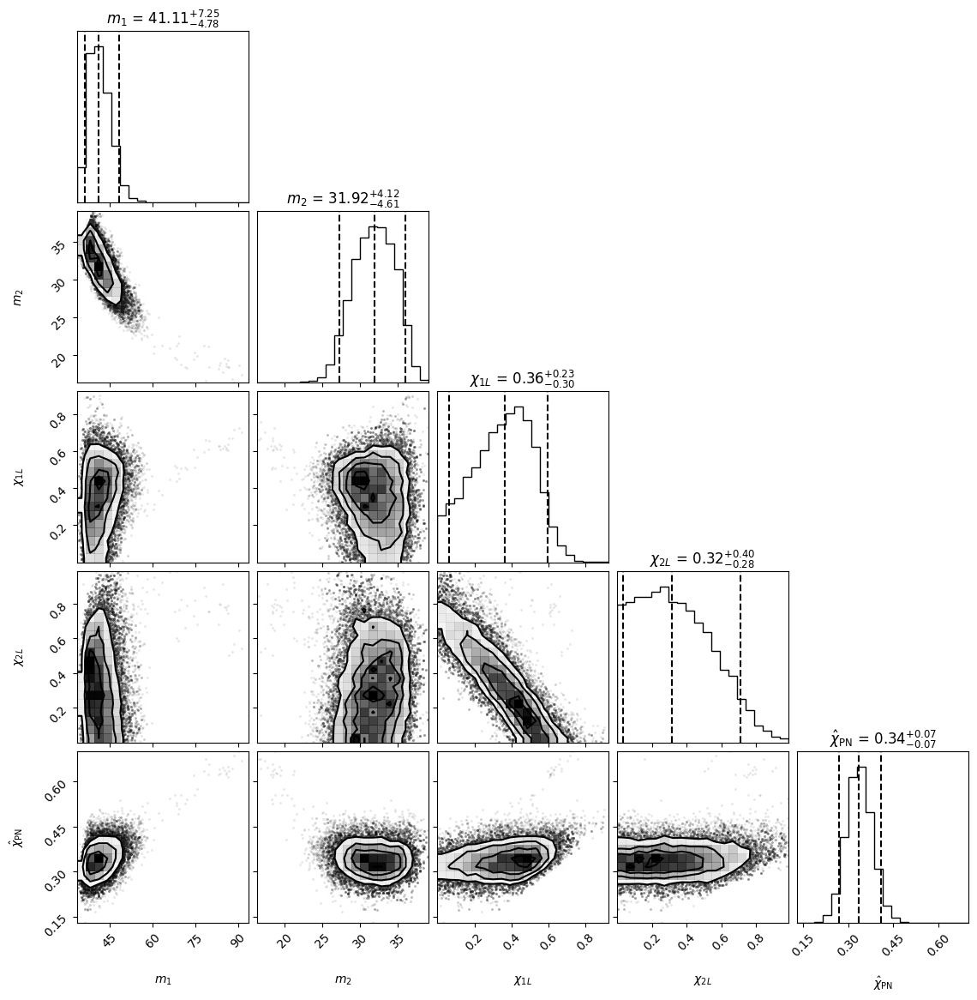

In [16]:
fig_path = "/mnt/d/Documents/workspace/课题/论文/figs"
quantiles = [0.05, 0.50, 0.95]
for j, cpsij in enumerate(cpsijs) :
    if cpsij == "gr" :
        par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'chi_hat_PN']
        corner.corner(samples[event_id][cpsij][par_list],
                      quantiles=quantiles,
                      show_titles=True,
                      #   title_kwargs={"fontsize":
                      hist_kwargs={"density": True},
                      labels=[r"$m_1$",r"$m_2$","$\chi_{{1L}}$","$\chi_{{2L}}$",r"$\hat{\chi}_\text{PN}$"])
        pp.savefig(fig_path + "/" + event_id + "" + "/posteriors" + f"/" + event_id + "_posterior_gr.pdf")
        continue
    par_list = ['mass1', 'mass2','spin1z', 'spin2z', 'chi_hat_PN', dchijs[j]]
    corner.corner(samples[event_id][cpsij][par_list],
                  quantiles=quantiles,
                  show_titles=True,
                  #   title_kwargs={"fontsize": 12},
                  hist_kwargs={"density": True},
                  labels=[r"$m_1$",r"$m_2$","$\chi_{{1L}}$","$\chi_{{2L}}$",r"$\hat{\chi}_\text{PN}$",f"$\\psi_{{{orders[j]}}}$"])
    pp.savefig(fig_path + "/" + event_id + "" + "/posteriors" + f"/" + event_id + f"_posterior_{cpsij}.pdf")

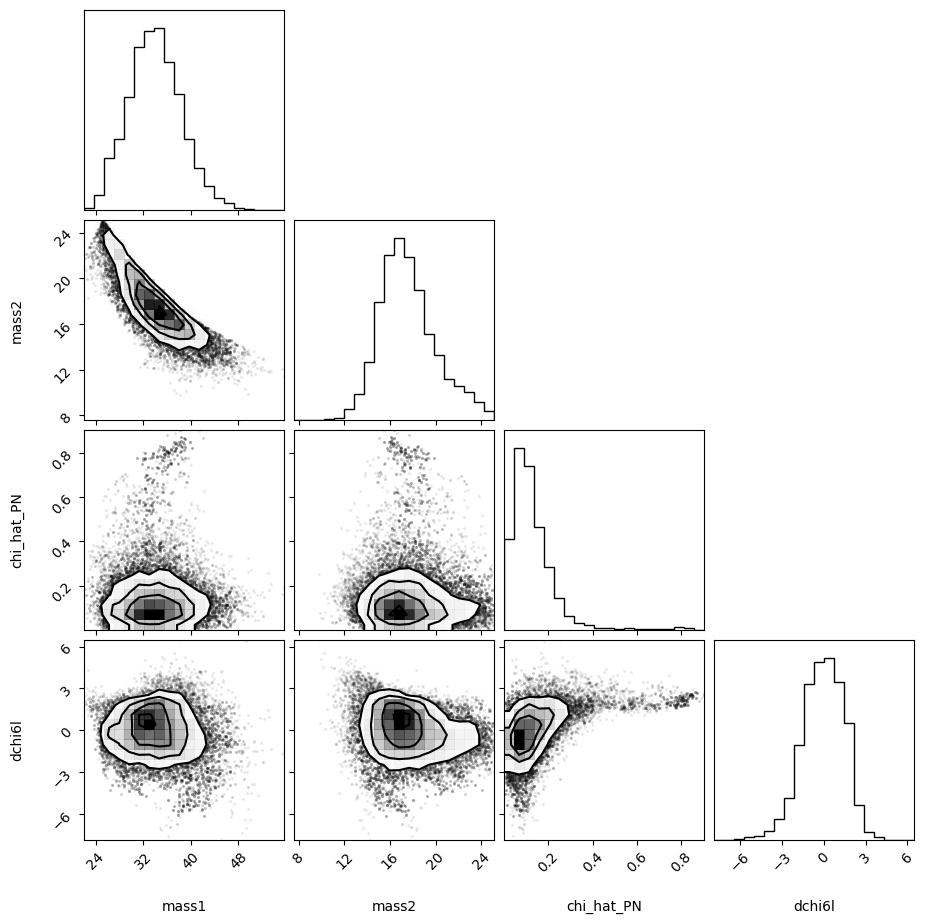

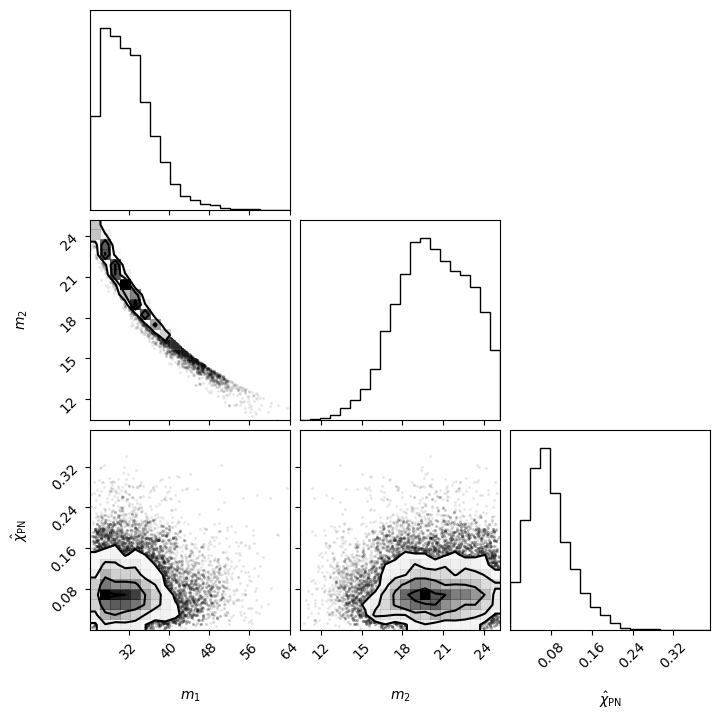

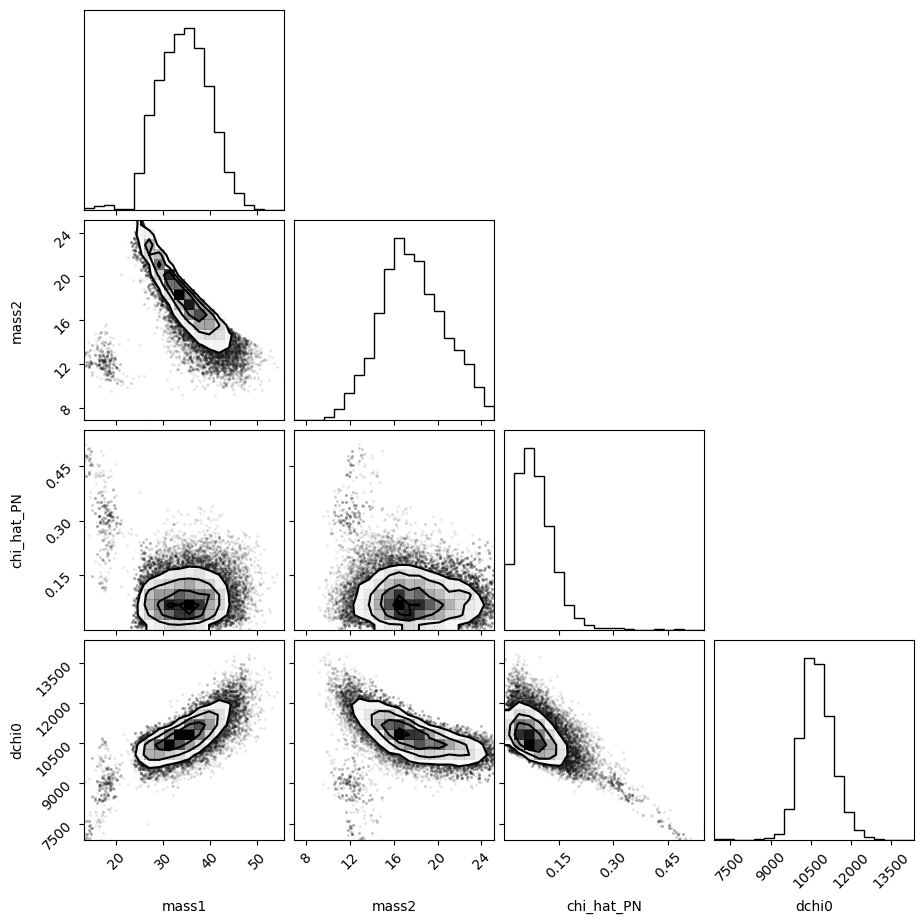

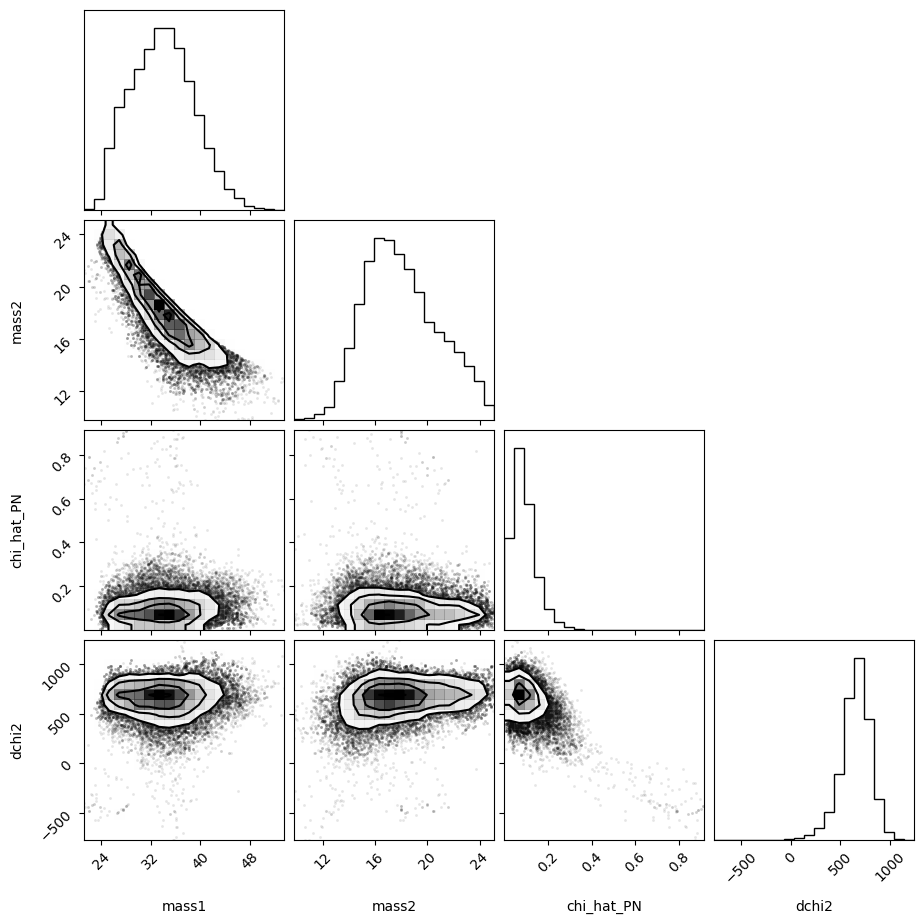

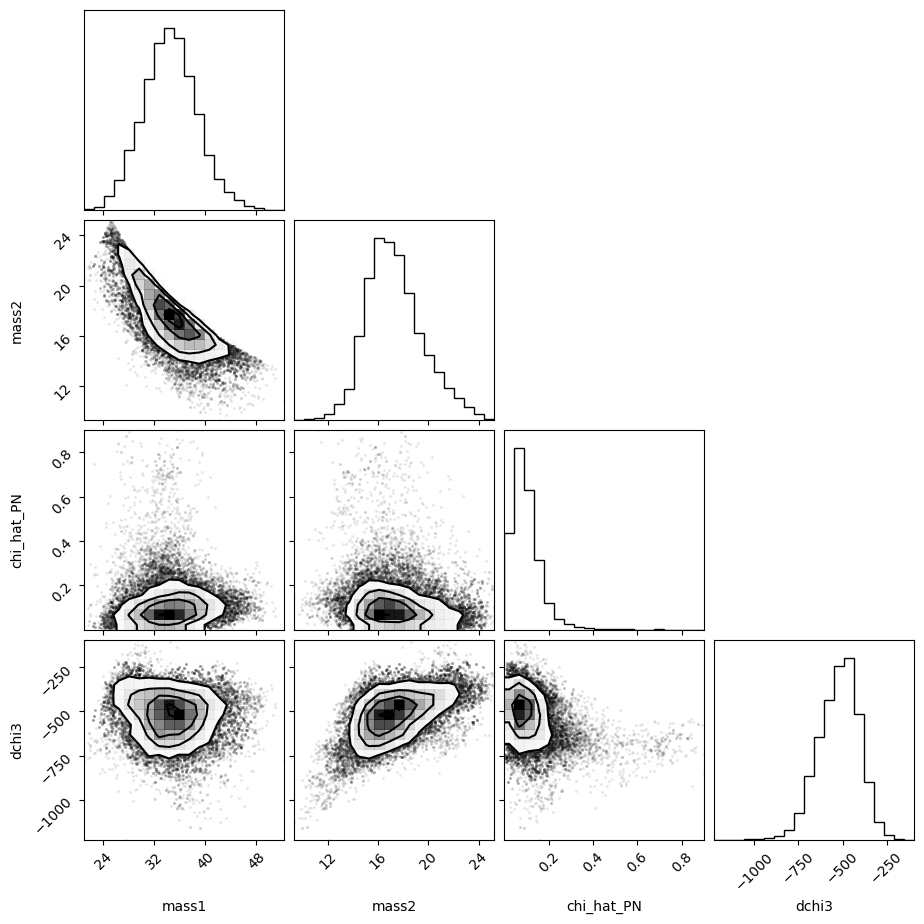

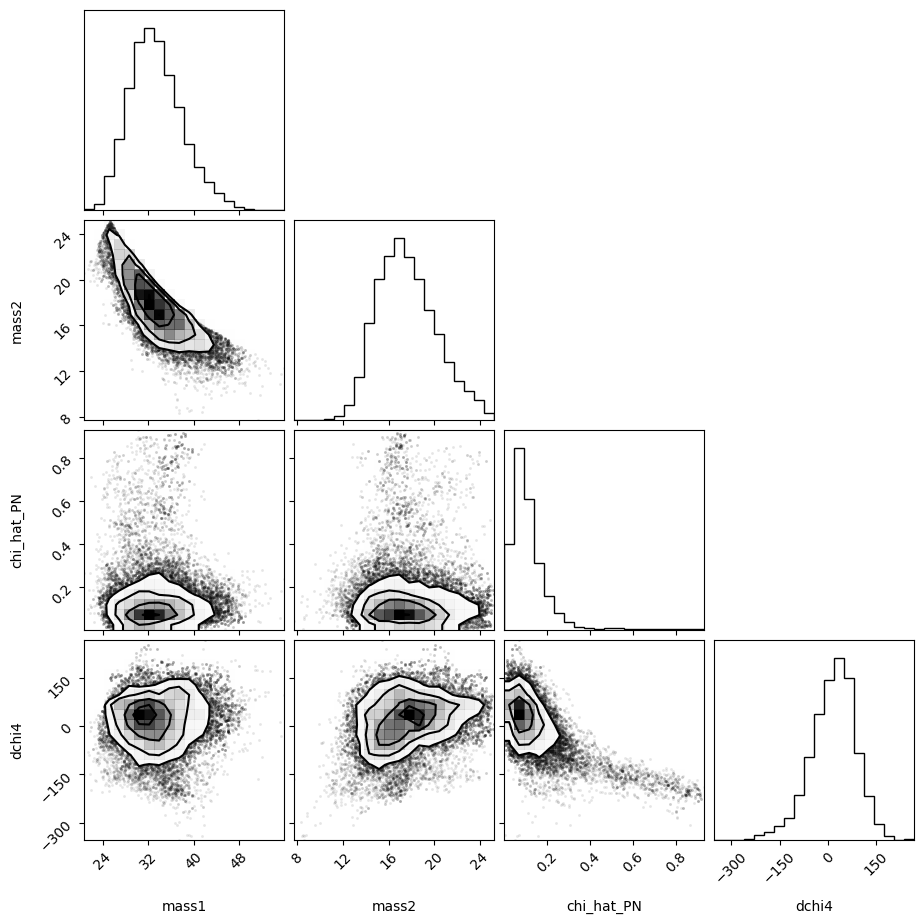

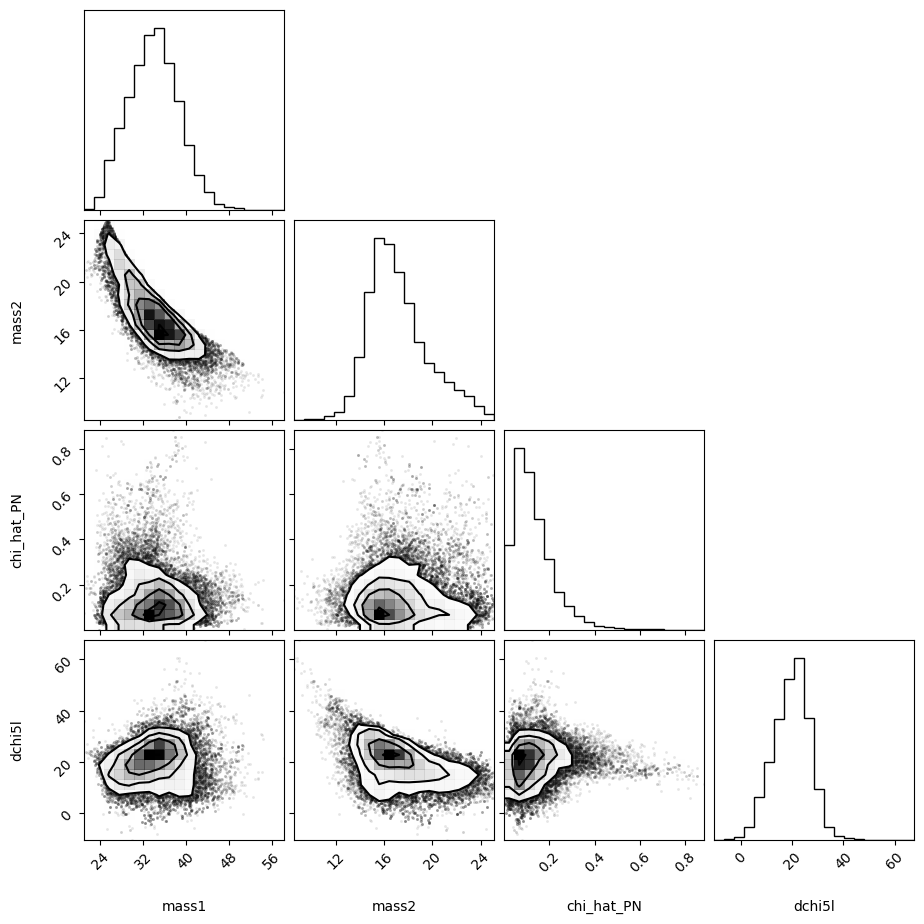

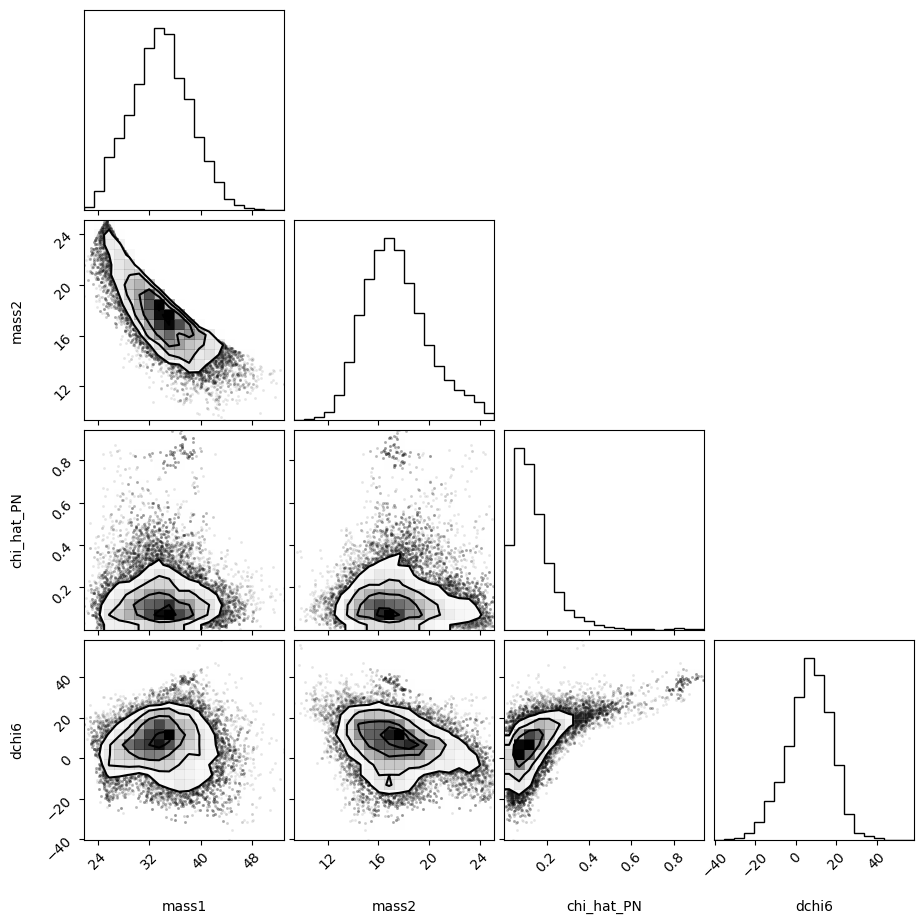

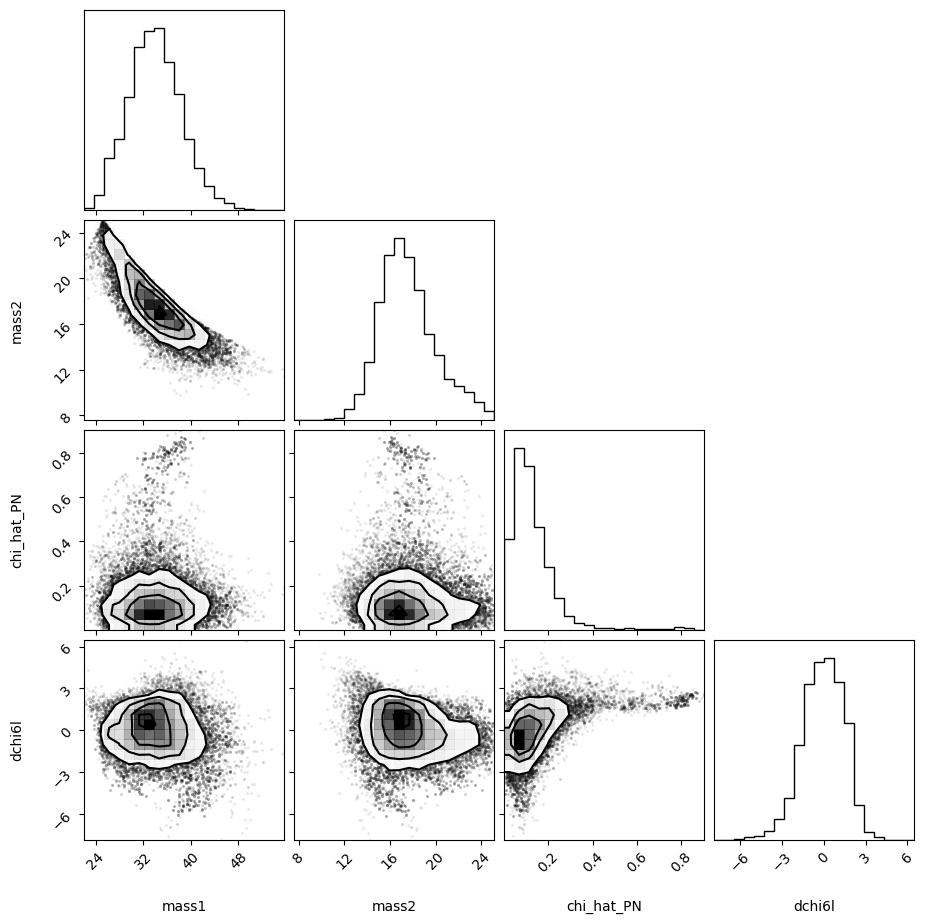

In [ ]:
par_list = ['mass1', 'mass2', 'chi_hat_PN']
corner.corner(samples[event_id]['gr'][par_list], labels=[r"$m_1$",r"$m_2$",r"$\hat{\chi}_\text{PN}$"])
pp.savefig(fig_path + "/GW150914" + "/posteriors" + "/GW150914_posterior_gr.pdf")
par_list = ['mass1', 'mass2', 'chi_hat_PN', 'dchi0']
corner.corner(samples[event_id]['cpsi0'][par_list], labels=par_list)
par_list = ['mass1', 'mass2', 'chi_hat_PN', 'dchi2']
corner.corner(samples[event_id]['cpsi2'][par_list], labels=par_list)
par_list = ['mass1', 'mass2', 'chi_hat_PN', 'dchi3']
corner.corner(samples[event_id]['cpsi3'][par_list], labels=par_list)
par_list = ['mass1', 'mass2', 'chi_hat_PN', 'dchi4']
corner.corner(samples[event_id]['cpsi4'][par_list], labels=par_list)
par_list = ['mass1', 'mass2', 'chi_hat_PN', 'dchi5l']
corner.corner(samples[event_id]['cpsi5l'][par_list], labels=par_list)
par_list = ['mass1', 'mass2', 'chi_hat_PN', 'dchi6']
corner.corner(samples[event_id]['cpsi6'][par_list], labels=par_list)
par_list = ['mass1', 'mass2', 'chi_hat_PN', 'dchi6l']
corner.corner(samples[event_id]['cpsi6l'][par_list], labels=par_list)

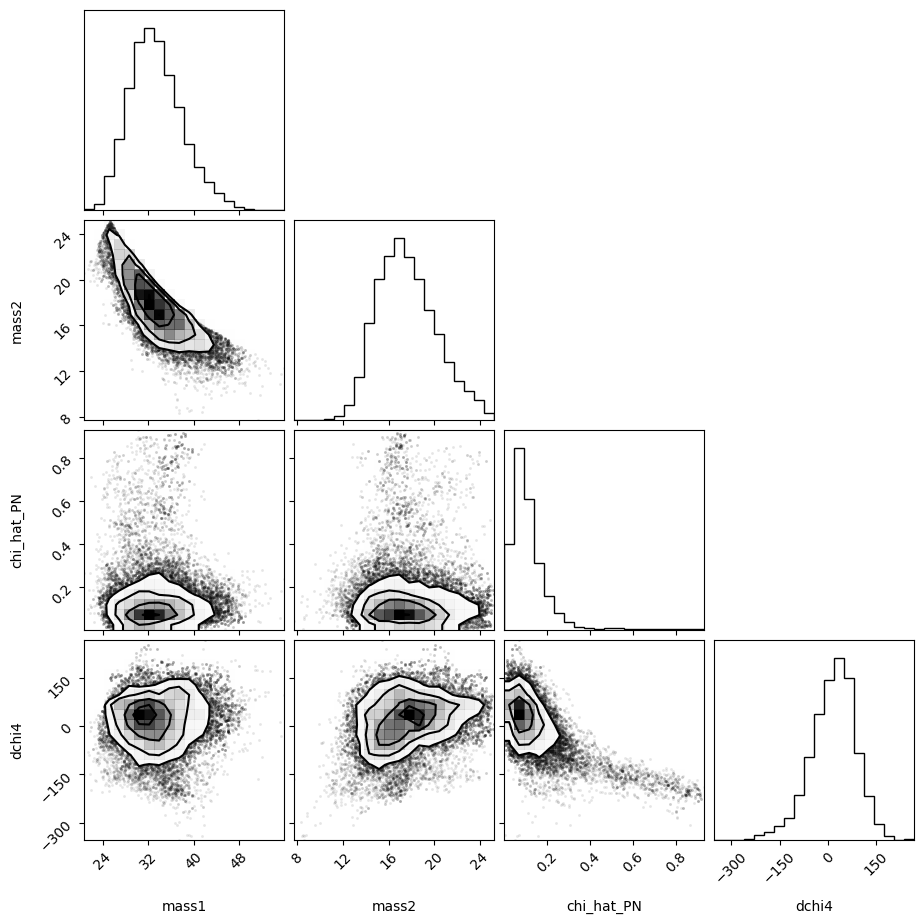

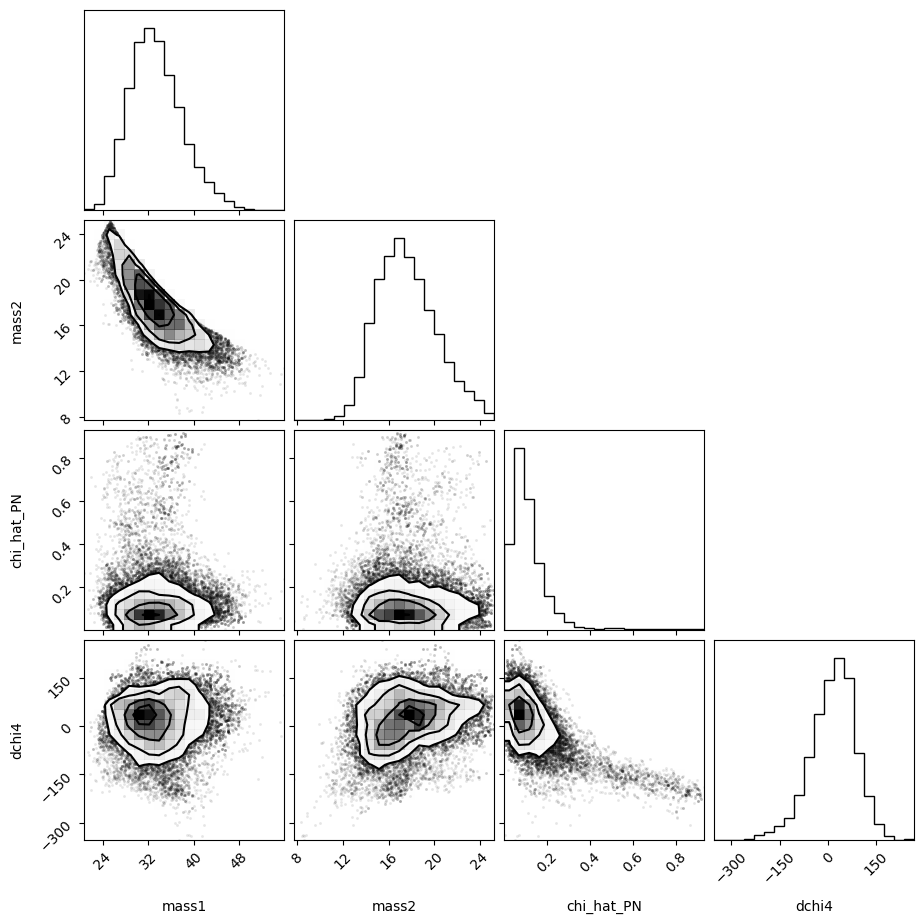

In [ ]:
par_list = ['mass1', 'mass2', 'chi_hat_PN', 'dchi4']
corner.corner(samples[event_id]['cpsi4'][par_list], labels=par_list)